### 1. Data Loading and Exploratory Data Analysis (EDA)
We will first load the cardiovascular dataset and inspect its structure, shape, statistical summary, and any missing values.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Load the dataset using the semicolon delimiter which is common in this specific dataset
df = pd.read_csv('/content/cardio_train[1].csv', sep=';')

# Display basic information
print("Dataset Shape:", df.shape)
print("\nDataset Information:")
display(df.info())
print("\nFirst 5 rows:")
display(df.head())


Dataset Shape: (70000, 13)

Dataset Information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 70000 entries, 0 to 69999
Data columns (total 13 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   id           70000 non-null  int64  
 1   age          70000 non-null  int64  
 2   gender       70000 non-null  int64  
 3   height       70000 non-null  int64  
 4   weight       70000 non-null  float64
 5   ap_hi        70000 non-null  int64  
 6   ap_lo        70000 non-null  int64  
 7   cholesterol  70000 non-null  int64  
 8   gluc         70000 non-null  int64  
 9   smoke        70000 non-null  int64  
 10  alco         70000 non-null  int64  
 11  active       70000 non-null  int64  
 12  cardio       70000 non-null  int64  
dtypes: float64(1), int64(12)
memory usage: 6.9 MB


None


First 5 rows:


,id,age,gender,height,weight,ap_hi,ap_lo,cholesterol,gluc,smoke,alco,active,cardio
0,0,18393,2,168,62.0,110,80,1,1,0,0,1,0
1,1,20228,1,156,85.0,140,90,3,1,0,0,1,1
2,2,18857,1,165,64.0,130,70,3,1,0,0,0,1
3,3,17623,2,169,82.0,150,100,1,1,0,0,1,1
4,4,17474,1,156,56.0,100,60,1,1,0,0,0,0


### 2. Data Cleaning & Preprocessing
- Convert `age` from days to years.
- Check and handle duplicate records.
- Check for outliers in physical attributes like height, weight, and blood pressure (`ap_hi`, `ap_lo`).
- Perform train-test split, encoding, and feature scaling.

In [2]:
# Drop 'id' column as it is not a predictor
if 'id' in df.columns:
    df = df.drop(columns=['id'])

# Convert age from days to years
df['age'] = df['age'] / 365.25

# Remove duplicate rows
duplicates = df.duplicated().sum()
if duplicates > 0:
    print(f"Removing {duplicates} duplicate rows.")
    df = df.drop_duplicates()

# Filter out clear blood pressure outliers and physical anomalies
# Diastolic (ap_lo) should be positive and lower than Systolic (ap_hi)
# Normal physiological ranges: height > 100cm, weight > 30kg, 50 < ap_hi < 250, 30 < ap_lo < 150
df = df[(df['height'] >= 100) & (df['height'] <= 220)]
df = df[(df['weight'] >= 30) & (df['weight'] <= 200)]
df = df[(df['ap_hi'] >= 60) & (df['ap_hi'] <= 240)]
df = df[(df['ap_lo'] >= 40) & (df['ap_lo'] <= 180)]
df = df[df['ap_hi'] > df['ap_lo']]

print("Cleaned Dataset Shape:", df.shape)
display(df.describe())

Removing 24 duplicate rows.
Cleaned Dataset Shape: (68614, 12)


,age,gender,height,weight,ap_hi,ap_lo,cholesterol,gluc,smoke,alco,active,cardio
count,68614.000000,68614.000000,68614.000000,68614.000000,68614.000000,68614.000000,68614.000000,68614.000000,68614.000000,68614.000000,68614.000000,68614.000000
mean,53.291542,1.348704,164.394526,74.121971,126.677282,81.306745,1.364838,1.225872,0.087985,0.053371,0.803349,0.494797
std,6.757625,0.476564,7.978134,14.308344,16.695890,9.448273,0.679006,0.571750,0.283275,0.224774,0.397469,0.499977
min,29.563313,1.000000,100.000000,30.000000,60.000000,40.000000,1.000000,1.000000,0.000000,0.000000,0.000000,0.000000
25%,48.344969,1.000000,159.000000,65.000000,120.000000,80.000000,1.000000,1.000000,0.000000,0.000000,1.000000,0.000000
50%,53.939767,1.000000,165.000000,72.000000,120.000000,80.000000,1.000000,1.000000,0.000000,0.000000,1.000000,0.000000
75%,58.384668,2.000000,170.000000,82.000000,140.000000,90.000000,2.000000,1.000000,0.000000,0.000000,1.000000,1.000000
max,64.922656,2.000000,207.000000,200.000000,240.000000,180.000000,3.000000,3.000000,1.000000,1.000000,1.000000,1.000000


In [3]:
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

# Define target and features
X = df.drop(columns=['cardio'])
y = df['cardio']

# Split data into train and test sets (80-20 split)
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)

# Scale continuous features ('age', 'height', 'weight', 'ap_hi', 'ap_lo')
scaler = StandardScaler()
continuous_cols = ['age', 'height', 'weight', 'ap_hi', 'ap_lo']

X_train_scaled = X_train.copy()
X_test_scaled = X_test.copy()

X_train_scaled[continuous_cols] = scaler.fit_transform(X_train[continuous_cols])
X_test_scaled[continuous_cols] = scaler.transform(X_test[continuous_cols])

print("Preprocessing completed. Features scaled successfully.")

Preprocessing completed. Features scaled successfully.


### 3. Model Development and Training
We will now train the following four models:
1. **Decision Tree Classifier**
2. **Naive Bayes Classifier**
3. **K-Nearest Neighbors (KNN)**
4. **Artificial Neural Network (Multi-Layer Perceptron)**

We will evaluate each model using Accuracy, Precision, Recall, and F1-score on the test dataset, and display their confusion matrices.

In [4]:
from sklearn.tree import DecisionTreeClassifier
from sklearn.naive_bayes import GaussianNB
from sklearn.neighbors import KNeighborsClassifier
from sklearn.neural_network import MLPClassifier
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, confusion_matrix, classification_report

# Initialize the models
models = {
    'Decision Tree': DecisionTreeClassifier(max_depth=6, random_state=42),
    'Naive Bayes': GaussianNB(),
    'KNN': KNeighborsClassifier(n_neighbors=9),
    'ANN (MLP)': MLPClassifier(hidden_layer_sizes=(64, 32), max_iter=500, random_state=42)
}

results = {}
confusion_matrices = {}

# Train and evaluate each model
for name, model in models.items():
    print(f"Training {name}...")
    # Use scaled features for distance/gradient based models
    if name in ['KNN', 'ANN (MLP)']:
        model.fit(X_train_scaled, y_train)
        predictions = model.predict(X_test_scaled)
    else:
        model.fit(X_train, y_train)
        predictions = model.predict(X_test)

    # Calculate metrics
    acc = accuracy_score(y_test, predictions)
    prec = precision_score(y_test, predictions)
    rec = recall_score(y_test, predictions)
    f1 = f1_score(y_test, predictions)

    results[name] = {
        'Accuracy': acc,
        'Precision': prec,
        'Recall': rec,
        'F1-Score': f1
    }
    confusion_matrices[name] = confusion_matrix(y_test, predictions)

    print(f"{name} metrics:")
    print(classification_report(y_test, predictions))
    print("-" * 50)

Training Decision Tree...
Decision Tree metrics:
              precision    recall  f1-score   support

           0       0.70      0.81      0.75      6933
           1       0.77      0.65      0.71      6790

    accuracy                           0.73     13723
   macro avg       0.74      0.73      0.73     13723
weighted avg       0.74      0.73      0.73     13723

--------------------------------------------------
Training Naive Bayes...
Naive Bayes metrics:
              precision    recall  f1-score   support

           0       0.68      0.82      0.74      6933
           1       0.77      0.61      0.68      6790

    accuracy                           0.71     13723
   macro avg       0.72      0.71      0.71     13723
weighted avg       0.72      0.71      0.71     13723

--------------------------------------------------
Training KNN...
KNN metrics:
              precision    recall  f1-score   support

           0       0.71      0.74      0.72      6933
           1

### 4. Comparison and Performance Evaluation
Let us visually compare the metrics and display the Confusion Matrices for all four classifiers.

Summary of Results:


,Accuracy,Precision,Recall,F1-Score
Decision Tree,0.730963,0.769485,0.651399,0.705535
Naive Bayes,0.713838,0.766723,0.606038,0.676976
KNN,0.715004,0.722179,0.689102,0.705253
ANN (MLP),0.732056,0.757230,0.674816,0.713652


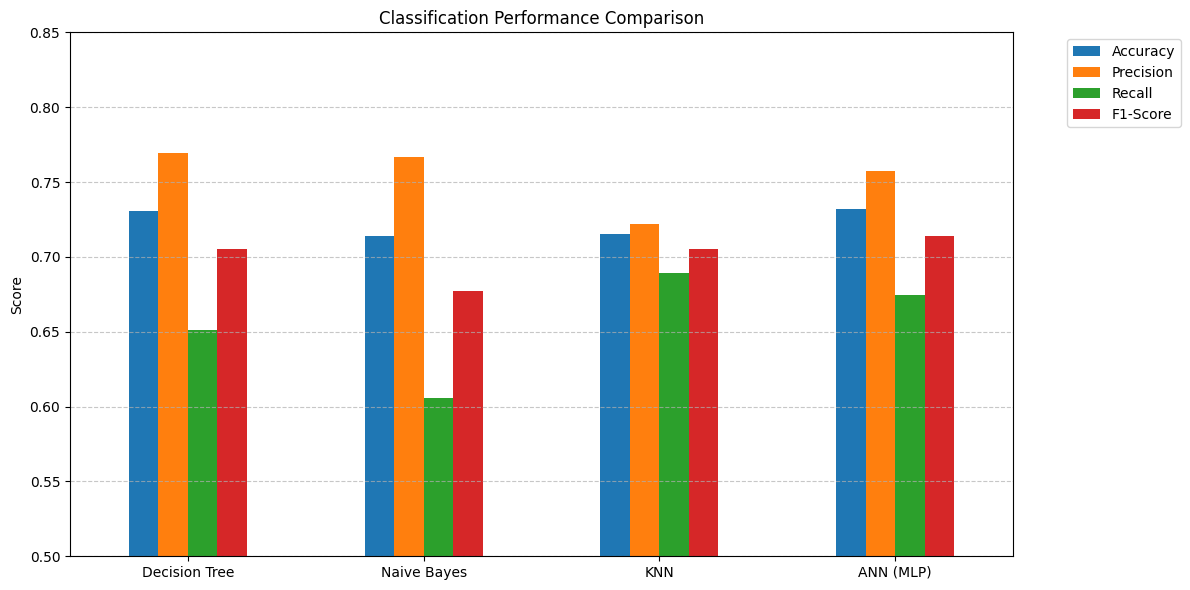

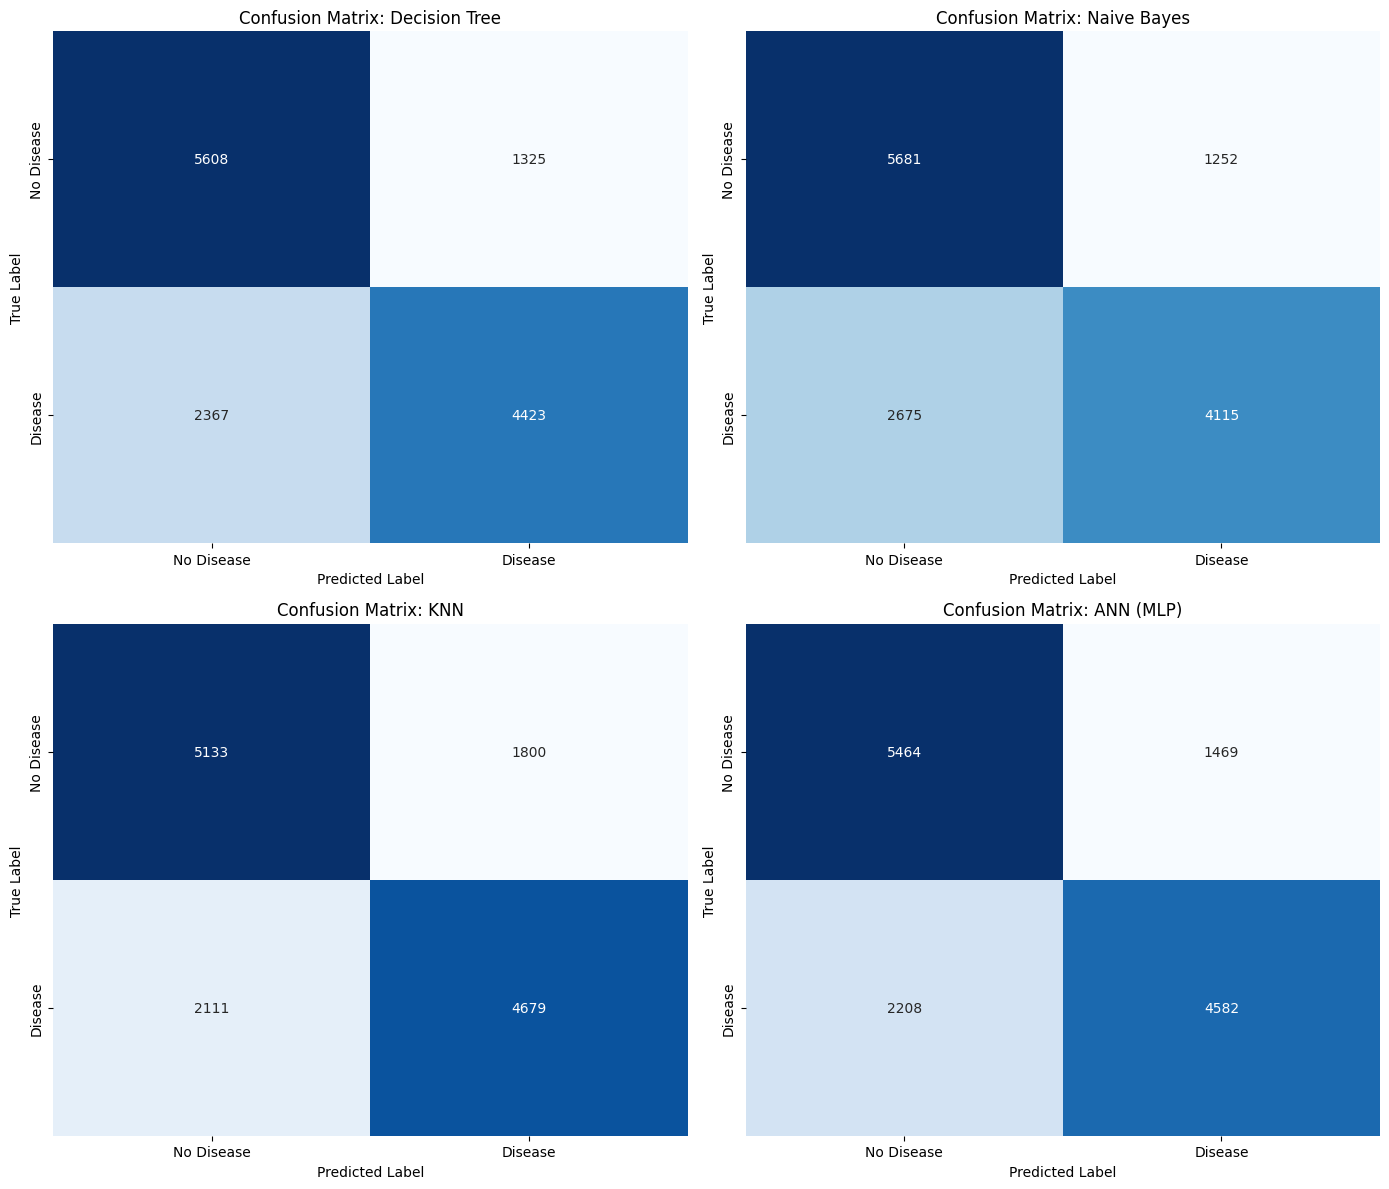

In [5]:
# Plot comparison metrics
results_df = pd.DataFrame(results).T
print("Summary of Results:")
display(results_df)

results_df.plot(kind='bar', figsize=(12, 6))
plt.title('Classification Performance Comparison')
plt.ylabel('Score')
plt.ylim(0.5, 0.85)
plt.xticks(rotation=0)
plt.grid(axis='y', linestyle='--', alpha=0.7)
plt.legend(bbox_to_anchor=(1.05, 1), loc='upper left')
plt.tight_layout()
plt.show()

# Plot Confusion Matrices side-by-side
fig, axes = plt.subplots(2, 2, figsize=(14, 12))
axes = axes.ravel()

for i, (name, cm) in enumerate(confusion_matrices.items()):
    sns.heatmap(cm, annot=True, fmt='d', ax=axes[i], cmap='Blues', cbar=False,
                xticklabels=['No Disease', 'Disease'], yticklabels=['No Disease', 'Disease'])
    axes[i].set_title(f'Confusion Matrix: {name}')
    axes[i].set_xlabel('Predicted Label')
    axes[i].set_ylabel('True Label')

plt.tight_layout()
plt.show()

### 5. Feature Importance Analysis (Decision Tree)
We will analyze feature importance values from the Decision Tree to see which clinical parameters drive the predictions.

/tmp/ipykernel_1187/49421644.py:7: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=importances[indices], y=X.columns[indices], palette="viridis")


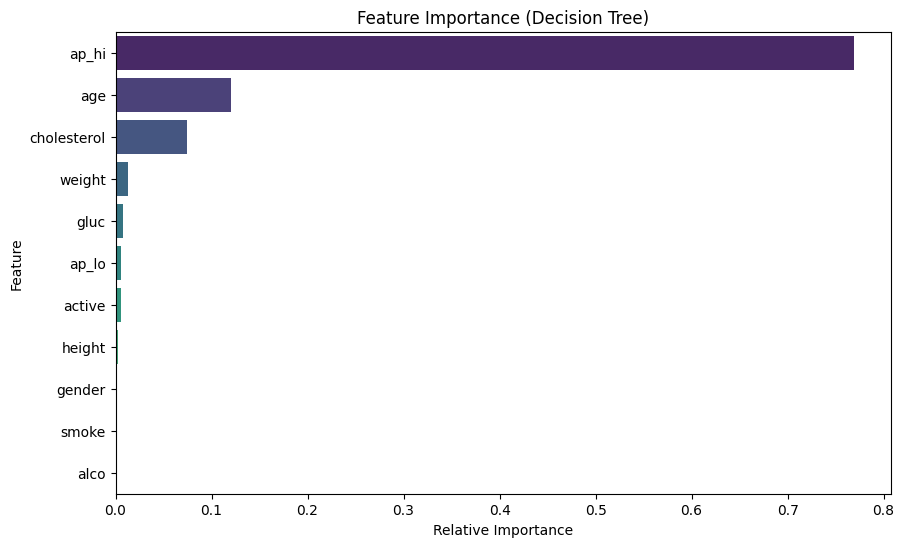

In [6]:
dt_model = models['Decision Tree']
importances = dt_model.feature_importances_
indices = np.argsort(importances)[::-1]

plt.figure(figsize=(10, 6))
plt.title("Feature Importance (Decision Tree)")
sns.barplot(x=importances[indices], y=X.columns[indices], palette="viridis")
plt.xlabel("Relative Importance")
plt.ylabel("Feature")
plt.show()